In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [60]:
columns = [
    "unit_number",
    "time_cycles",
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3",
    "sensor_1",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_5",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_16",
    "sensor_17",
    "sensor_18",
    "sensor_19",
    "sensor_20",
    "sensor_21"
]

In [61]:
train_df = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

train_df.head()

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [62]:
train_df.shape

(20631, 26)

In [63]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   unit_number            20631 non-null  int64  
 1   time_cycles            20631 non-null  int64  
 2   operational_setting_1  20631 non-null  float64
 3   operational_setting_2  20631 non-null  float64
 4   operational_setting_3  20631 non-null  float64
 5   sensor_1               20631 non-null  float64
 6   sensor_2               20631 non-null  float64
 7   sensor_3               20631 non-null  float64
 8   sensor_4               20631 non-null  float64
 9   sensor_5               20631 non-null  float64
 10  sensor_6               20631 non-null  float64
 11  sensor_7               20631 non-null  float64
 12  sensor_8               20631 non-null  float64
 13  sensor_9               20631 non-null  float64
 14  sensor_10              20631 non-null  float64
 15  se

In [64]:
train_df.isnull().sum()

unit_number              0
time_cycles              0
operational_setting_1    0
operational_setting_2    0
operational_setting_3    0
sensor_1                 0
sensor_2                 0
sensor_3                 0
sensor_4                 0
sensor_5                 0
sensor_6                 0
sensor_7                 0
sensor_8                 0
sensor_9                 0
sensor_10                0
sensor_11                0
sensor_12                0
sensor_13                0
sensor_14                0
sensor_15                0
sensor_16                0
sensor_17                0
sensor_18                0
sensor_19                0
sensor_20                0
sensor_21                0
dtype: int64

In [65]:
train_df["unit_number"].nunique()

100

In [66]:
train_df.groupby("unit_number")["time_cycles"].max()

unit_number
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: time_cycles, Length: 100, dtype: int64

In [67]:
max_cycles = train_df.groupby("unit_number")["time_cycles"].max()

train_df["RUL"] = train_df["unit_number"].map(max_cycles) - train_df["time_cycles"]

train_df.head()

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [68]:
train_df["RUL"].describe()

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

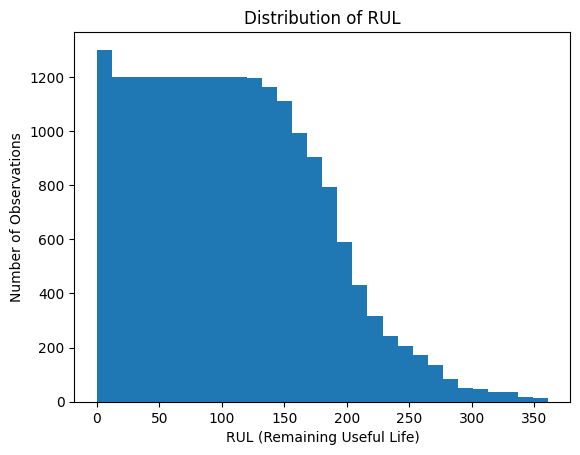

In [69]:
plt.hist(train_df["RUL"], bins=30)
plt.xlabel("RUL (Remaining Useful Life)")
plt.ylabel("Number of Observations")
plt.title("Distribution of RUL")
plt.show()

In [70]:
train_df.describe()

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705,107.807862
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,1.776400e-15,...,0.071919,19.076176,0.037505,1.387812e-17,1.548763,0.0,0.0,0.180746,0.108251,68.880990
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200,0.000000
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800,51.000000
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900,103.000000
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800,155.000000
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400,361.000000


In [71]:
train_df.nunique()

unit_number               100
time_cycles               362
operational_setting_1     158
operational_setting_2      13
operational_setting_3       1
sensor_1                    1
sensor_2                  310
sensor_3                 3012
sensor_4                 4051
sensor_5                    1
sensor_6                    2
sensor_7                  513
sensor_8                   53
sensor_9                 6403
sensor_10                   1
sensor_11                 159
sensor_12                 427
sensor_13                  56
sensor_14                6078
sensor_15                1918
sensor_16                   1
sensor_17                  13
sensor_18                   1
sensor_19                   1
sensor_20                 120
sensor_21                4745
RUL                       362
dtype: int64

In [72]:
train_df.corr(numeric_only=True)["RUL"].sort_values()

time_cycles             -0.736241
sensor_11               -0.696228
sensor_4                -0.678948
sensor_15               -0.642667
sensor_2                -0.606484
sensor_17               -0.606154
sensor_3                -0.584520
sensor_8                -0.563968
sensor_13               -0.562569
sensor_9                -0.390102
sensor_14               -0.306769
sensor_6                -0.128348
operational_setting_1   -0.003198
operational_setting_2   -0.001948
unit_number              0.078753
sensor_20                0.629428
sensor_21                0.635662
sensor_7                 0.657223
sensor_12                0.671983
RUL                      1.000000
operational_setting_3         NaN
sensor_1                      NaN
sensor_5                      NaN
sensor_10                     NaN
sensor_16                     NaN
sensor_18                     NaN
sensor_19                     NaN
Name: RUL, dtype: float64

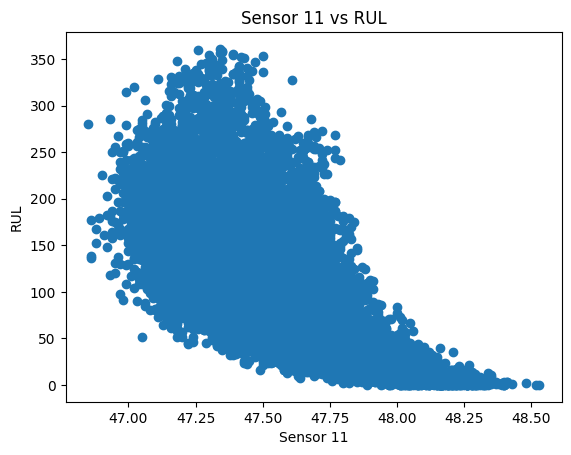

In [73]:
plt.scatter(train_df["sensor_11"], train_df["RUL"])
plt.xlabel("Sensor 11")
plt.ylabel("RUL")
plt.title("Sensor 11 vs RUL")
plt.show()

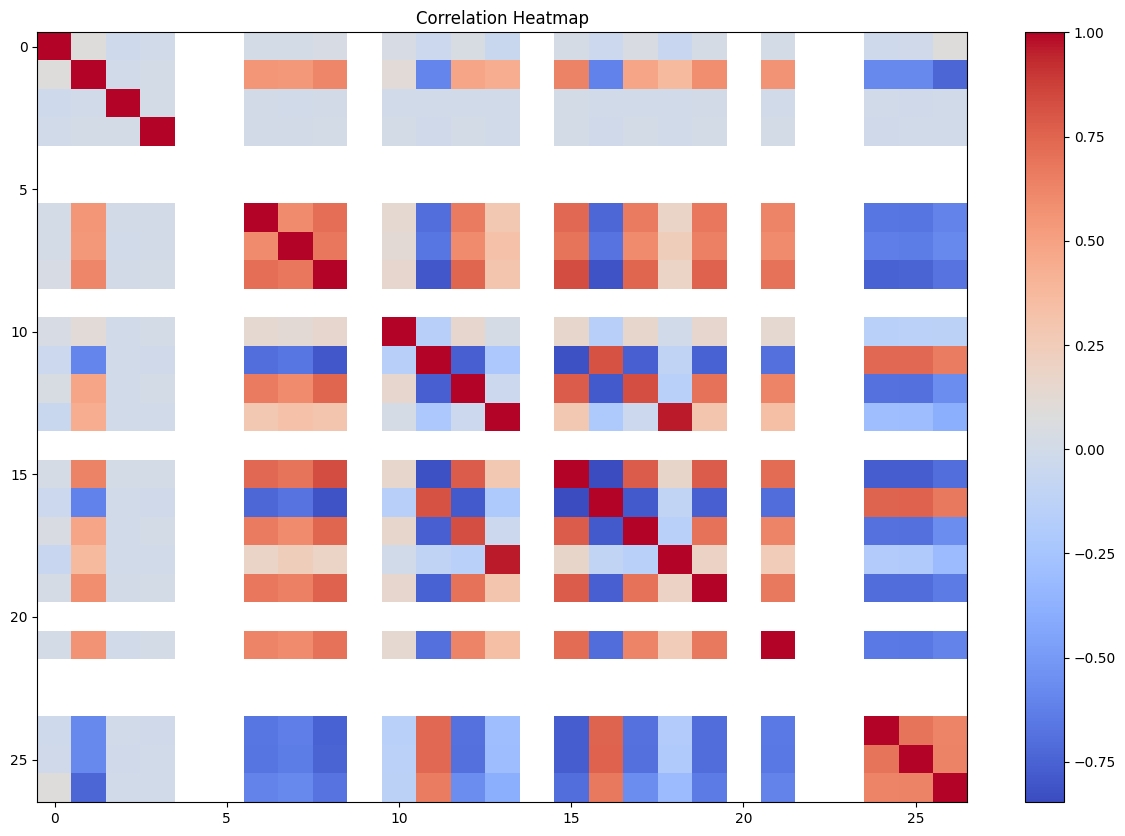

In [74]:
corr = train_df.corr(numeric_only=True)

plt.figure(figsize=(15, 10))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()
plt.title("Correlation Heatmap")
plt.show()

In [75]:
constant_columns = train_df.columns[train_df.nunique() == 1]

constant_columns

Index(['operational_setting_3', 'sensor_1', 'sensor_5', 'sensor_10',
       'sensor_16', 'sensor_18', 'sensor_19'],
      dtype='object')

In [76]:
train_clean = train_df.drop(columns=constant_columns)

train_clean.shape

(20631, 20)

In [77]:
train_clean.columns

Index(['unit_number', 'time_cycles', 'operational_setting_1',
       'operational_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6',
       'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12',
       'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20',
       'sensor_21', 'RUL'],
      dtype='object')

In [78]:
X = train_clean.drop(columns=["RUL"])
y = train_clean["RUL"]

print(X.shape)
print(y.shape)

(20631, 19)
(20631,)


In [79]:
test_df = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

test_df.head()

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [80]:
test_df.shape

(13096, 26)

In [81]:
test_df["unit_number"].nunique()

100

In [82]:
constant_columns

Index(['operational_setting_3', 'sensor_1', 'sensor_5', 'sensor_10',
       'sensor_16', 'sensor_18', 'sensor_19'],
      dtype='object')

In [83]:
test_clean = test_df.drop(columns=constant_columns)

In [84]:
test_clean.shape

(13096, 19)

In [85]:
rul = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\RUL_FD001.txt",
    header=None
)

rul.head()

,0
0,112
1,98
2,69
3,82
4,91


In [86]:
rul.shape

(100, 1)

In [87]:
rul[0].head(10)

0    112
1     98
2     69
3     82
4     91
5     93
6     91
7     95
8    111
9     96
Name: 0, dtype: int64

In [88]:
test_last_cycle = test_df.groupby("unit_number")["time_cycles"].max()

test_last_cycle.head(10)

unit_number
1      31
2      49
3     126
4     106
5      98
6     105
7     160
8     166
9      55
10    192
Name: time_cycles, dtype: int64

In [89]:
test_final = test_df.groupby("unit_number").tail(1)

test_final.head(10)

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,521.79,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,521.74,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,520.83,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,521.88,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,521.00,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117
514,6,105,0.0076,-0.0003,100.0,518.67,643.05,1586.94,1404.49,14.62,...,521.56,2388.15,8139.02,8.4452,0.03,393,2388,100.0,38.91,23.3269
674,7,160,0.0016,-0.0001,100.0,518.67,642.10,1589.59,1413.57,14.62,...,522.32,2388.07,8149.19,8.4028,0.03,393,2388,100.0,38.91,23.2763
840,8,166,0.0016,-0.0005,100.0,518.67,642.59,1591.91,1413.89,14.62,...,520.53,2388.12,8127.84,8.4744,0.03,393,2388,100.0,38.73,23.2465
895,9,55,-0.0003,0.0004,100.0,518.67,642.27,1593.61,1410.27,14.62,...,521.65,2388.16,8134.76,8.4293,0.03,392,2388,100.0,38.78,23.3515
1087,10,192,-0.0018,0.0004,100.0,518.67,643.00,1589.50,1398.99,14.62,...,521.82,2388.08,8141.91,8.4194,0.03,393,2388,100.0,38.79,23.2956


In [90]:
test_final.shape

(100, 26)

In [91]:
X = train_clean.drop(columns=["RUL"])

In [92]:
X = X.drop(columns=["unit_number"])

In [93]:
X.shape

(20631, 18)

In [94]:
test_final

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,521.79,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,521.74,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,520.83,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,521.88,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,521.00,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12545,96,97,-0.0006,0.0003,100.0,518.67,642.30,1590.88,1397.94,14.62,...,522.30,2388.01,8148.24,8.4110,0.03,391,2388,100.0,38.96,23.4606
12679,97,134,0.0013,-0.0001,100.0,518.67,642.59,1582.96,1410.92,14.62,...,521.58,2388.06,8155.48,8.4500,0.03,395,2388,100.0,38.61,23.2953
12800,98,121,0.0017,0.0001,100.0,518.67,642.68,1599.51,1415.47,14.62,...,521.53,2388.09,8146.39,8.4235,0.03,394,2388,100.0,38.76,23.3608
12897,99,97,0.0047,-0.0000,100.0,518.67,642.00,1585.03,1397.98,14.62,...,521.82,2388.02,8150.38,8.4003,0.03,391,2388,100.0,38.95,23.3595


In [95]:
X_test = test_final.drop(columns=["unit_number"])

In [96]:
X_test.shape

(100, 25)

In [97]:
X_test = X_test.drop(columns=constant_columns)

In [98]:
X_test.shape

(100, 18)

In [99]:
X.columns.equals(X_test.columns)

True

In [100]:
y = train_clean["RUL"]
y.shape

(20631,)

In [101]:
y.head()

0    191
1    190
2    189
3    188
4    187
Name: RUL, dtype: int64

In [102]:
from sklearn.model_selection import GroupShuffleSplit

groups = train_clean["unit_number"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(gss.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (16561, 18)
X_val: (4070, 18)
y_train: (16561,)
y_val: (4070,)


In [103]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [104]:
y_pred_dt = dt_model.predict(X_val)

print(y_pred_dt[:10])

[337. 279. 138. 270. 182. 127. 312. 169. 178. 157.]


In [105]:
print(y_val.iloc[:10].values)

[191 190 189 188 187 186 185 184 183 182]


In [106]:
from sklearn.metrics import mean_absolute_error

mae_dt = mean_absolute_error(y_val, y_pred_dt)

print("Decision Tree MAE:", mae_dt)

Decision Tree MAE: 35.76437346437346


In [107]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [108]:
y_pred_rf = rf_model.predict(X_val)

print(y_pred_rf[:10])

[216.4  206.94 202.55 237.13 221.24 216.04 207.37 207.51 207.94 205.06]


In [109]:
from sklearn.metrics import mean_absolute_error

mae_rf = mean_absolute_error(y_val, y_pred_rf)

print("Random Forest MAE:", mae_rf)

Random Forest MAE: 23.997427518427518


In [110]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))

print("Random Forest RMSE:", rmse_rf)

Random Forest RMSE: 31.703415793071933


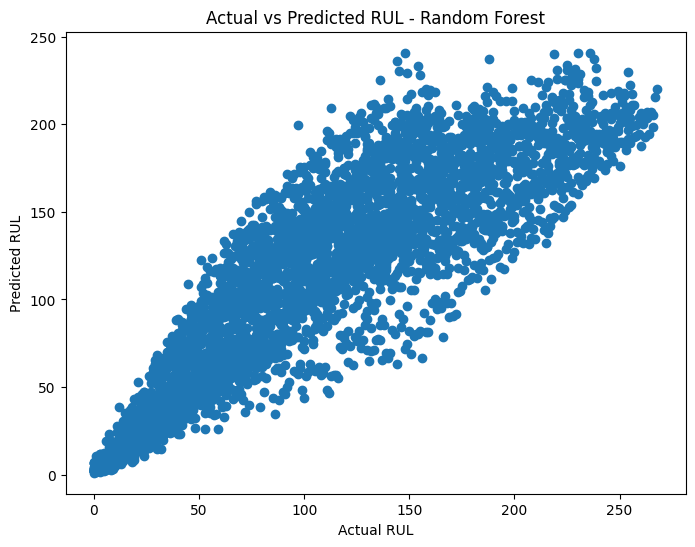

In [111]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred_rf)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Random Forest")

plt.show()

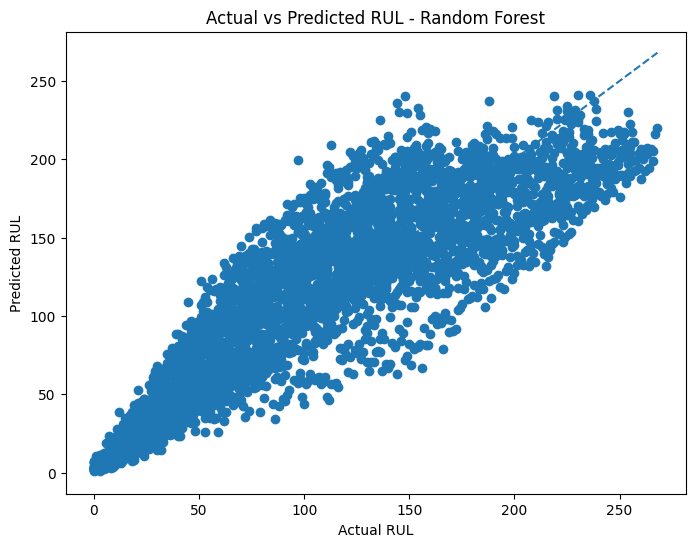

In [112]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred_rf)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Random Forest")

plt.show()

In [113]:
rmse_dt = np.sqrt(mean_squared_error(y_val, y_pred_dt))

print("Decision Tree RMSE:", rmse_dt)

Decision Tree RMSE: 49.54315370083014


In [114]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(feature_importance)

time_cycles              0.534460
sensor_11                0.143382
sensor_9                 0.045830
sensor_4                 0.031308
sensor_14                0.029860
sensor_12                0.027988
sensor_7                 0.023958
sensor_15                0.023113
sensor_21                0.021247
sensor_3                 0.020068
sensor_2                 0.018650
operational_setting_1    0.016392
sensor_20                0.016027
sensor_8                 0.015794
sensor_13                0.014125
operational_setting_2    0.010320
sensor_17                0.006772
sensor_6                 0.000706
dtype: float64


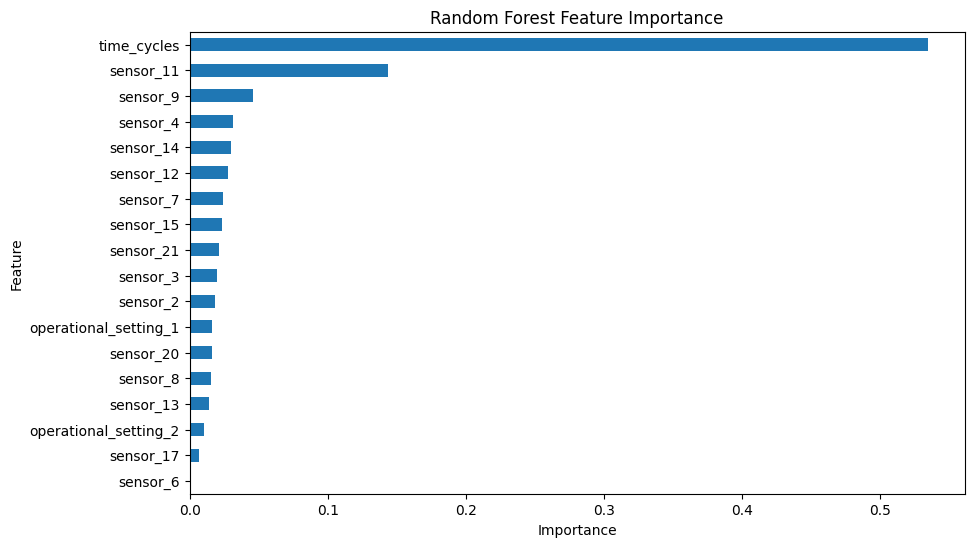

In [115]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.show()

In [116]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=42
)

gb_model.fit(X_train, y_train)

GradientBoostingRegressor(random_state=42)

In [117]:
y_pred_gb = gb_model.predict(X_val)

print(y_pred_gb[:10])

[215.66838158 207.55002635 206.82377723 214.93764164 208.84996673
 219.56186944 211.41965329 205.51408687 204.12161503 208.26207797]


In [118]:
from sklearn.metrics import mean_absolute_error

mae_gb = mean_absolute_error(y_val, y_pred_gb)

print("Gradient Boosting MAE:", mae_gb)

Gradient Boosting MAE: 22.69221239049367


In [119]:
rmse_gb = np.sqrt(mean_squared_error(y_val, y_pred_gb))

print("Gradient Boosting RMSE:", rmse_gb)

Gradient Boosting RMSE: 29.753710984677877


In [120]:
print(gb_model.get_params())

{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'friedman_mse', 'init': None, 'learning_rate': 0.1, 'loss': 'squared_error', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 100, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}


In [121]:
for n in [50, 100, 150, 200]:

    model = GradientBoostingRegressor(
        n_estimators=n,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, pred)

    print("n_estimators:", n, "MAE:", mae)

n_estimators: 50 MAE: 22.68697203477855
n_estimators: 100 MAE: 22.69221239049367
n_estimators: 150 MAE: 22.85615395311361
n_estimators: 200 MAE: 23.003140264559402


In [122]:
for lr in [0.03, 0.05, 0.1, 0.15, 0.2]:

    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=lr,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, pred)

    print("learning_rate:", lr, "MAE:", mae)

learning_rate: 0.03 MAE: 23.7338599030904
learning_rate: 0.05 MAE: 22.67694753890372
learning_rate: 0.1 MAE: 22.69221239049367
learning_rate: 0.15 MAE: 22.892497855210713
learning_rate: 0.2 MAE: 23.16914410865018


In [123]:
for depth in [2, 3, 4, 5]:

    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, pred)

    print("max_depth:", depth, "MAE:", mae)

max_depth: 2 MAE: 23.064723670771677
max_depth: 3 MAE: 22.67694753890372
max_depth: 4 MAE: 22.96080714475752
max_depth: 5 MAE: 23.191766019800053


In [124]:
for leaf in [1, 2, 5, 10]:

    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train, y_train)

    pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, pred)

    print("min_samples_leaf:", leaf, "MAE:", mae)

min_samples_leaf: 1 MAE: 22.67694753890372
min_samples_leaf: 2 MAE: 22.675968931872802
min_samples_leaf: 5 MAE: 22.68446565904336
min_samples_leaf: 10 MAE: 22.705645527241153


In [125]:
best_gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

best_gb_model.fit(X_train, y_train)

y_pred_best_gb = best_gb_model.predict(X_val)

mae_best_gb = mean_absolute_error(y_val, y_pred_best_gb)
rmse_best_gb = np.sqrt(mean_squared_error(y_val, y_pred_best_gb))

print("Gradient Boosting MAE:", mae_best_gb)
print("Gradient Boosting RMSE:", rmse_best_gb)

Gradient Boosting MAE: 22.675968931872802
Gradient Boosting RMSE: 29.552745021456314


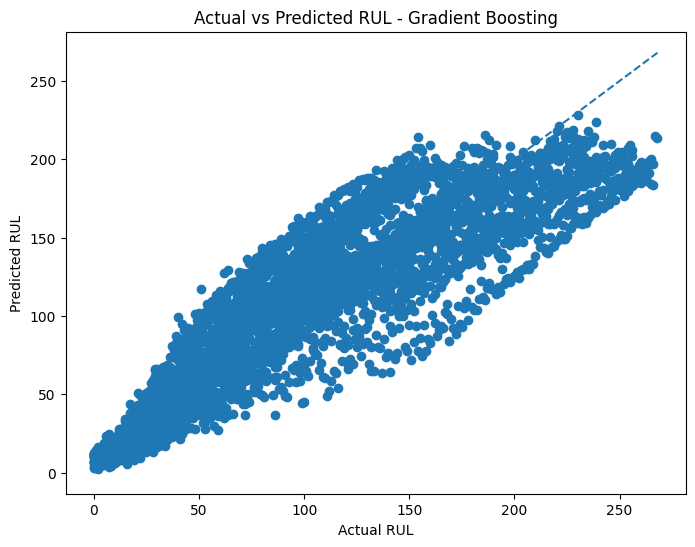

In [126]:
plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred_best_gb)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Gradient Boosting")

plt.show()

In [127]:
print("Training features:", X.shape)
print("Test features:", X_test.shape)
print("Same columns:", X.columns.equals(X_test.columns))

Training features: (20631, 18)
Test features: (100, 18)
Same columns: True


In [128]:
final_gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

final_gb_model.fit(X, y)

print("Final model trained successfully.")

Final model trained successfully.


In [129]:
y_pred_test = final_gb_model.predict(X_test)

print("Predicted RUL values:")
print(y_pred_test[:10])

Predicted RUL values:
[181.34250444 142.93596018  51.637851    87.21205795  97.49728449
 105.6400735   94.41370483  76.01358063 137.72611969  99.1432242 ]


In [130]:
actual_rul = rul[0].values

print("Actual RUL values:")
print(actual_rul[:10])

Actual RUL values:
[112  98  69  82  91  93  91  95 111  96]


In [131]:
final_mae = mean_absolute_error(actual_rul, y_pred_test)

print("Final Test MAE:", final_mae)

Final Test MAE: 18.143699851558864


In [132]:
final_rmse = np.sqrt(mean_squared_error(actual_rul, y_pred_test))

print("Final Test RMSE:", final_rmse)

Final Test RMSE: 24.861975055606695


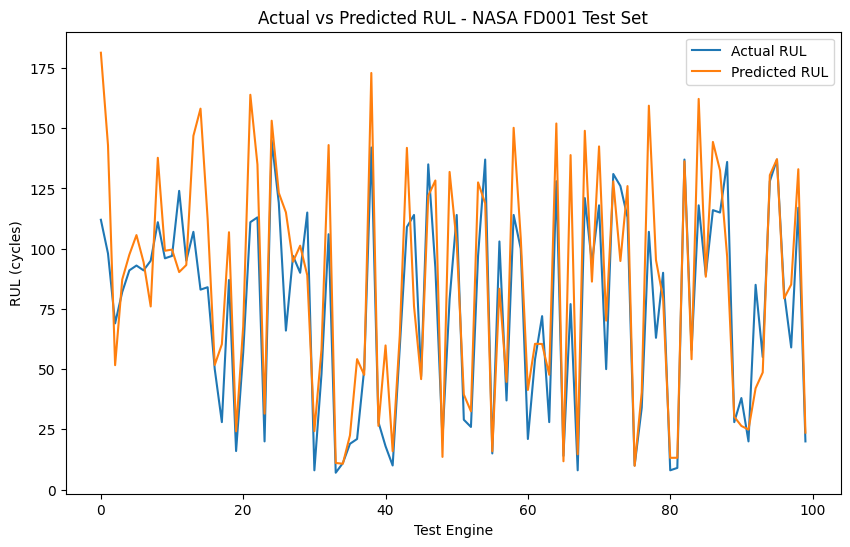

In [133]:
plt.figure(figsize=(10, 6))

plt.plot(actual_rul, label="Actual RUL")
plt.plot(y_pred_test, label="Predicted RUL")

plt.xlabel("Test Engine")
plt.ylabel("RUL (cycles)")
plt.title("Actual vs Predicted RUL - NASA FD001 Test Set")
plt.legend()

plt.show()

In [134]:
model_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Validation MAE": [
        mae_dt,
        mae_rf,
        mae_best_gb
    ],
    "Validation RMSE": [
        rmse_dt,
        rmse_rf,
        rmse_best_gb
    ]
})

model_results

,Model,Validation MAE,Validation RMSE
0,Decision Tree,35.764373,49.543154
1,Random Forest,23.997428,31.703416
2,Gradient Boosting,22.675969,29.552745


In [135]:
feature_importance_gb = pd.Series(
    final_gb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(feature_importance_gb)

time_cycles              0.680496
sensor_11                0.093688
sensor_4                 0.071193
sensor_12                0.035097
sensor_9                 0.024879
sensor_7                 0.023650
sensor_15                0.017187
sensor_21                0.013712
sensor_14                0.010652
sensor_2                 0.009998
sensor_20                0.008149
sensor_3                 0.003237
sensor_17                0.002856
sensor_8                 0.002406
sensor_13                0.002360
operational_setting_1    0.000191
operational_setting_2    0.000146
sensor_6                 0.000102
dtype: float64


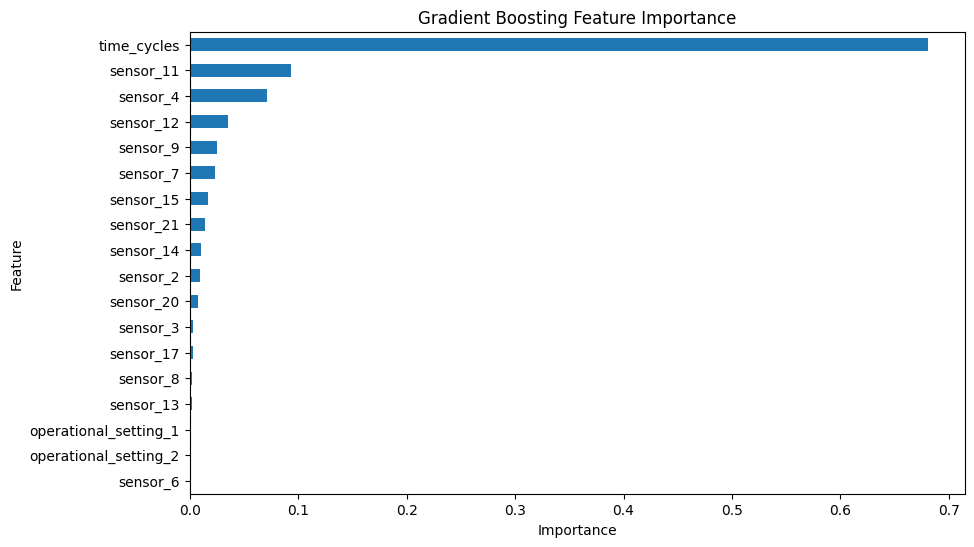

In [136]:
plt.figure(figsize=(10, 6))

feature_importance_gb.sort_values().plot(kind="barh")

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.show()

In [137]:
test_results = pd.DataFrame({
    "Engine": range(1, 101),
    "Actual_RUL": actual_rul,
    "Predicted_RUL": y_pred_test
})

test_results["Absolute_Error"] = (
    abs(test_results["Actual_RUL"] - test_results["Predicted_RUL"])
)

test_results.head(10)

,Engine,Actual_RUL,Predicted_RUL,Absolute_Error
0,1,112,181.342504,69.342504
1,2,98,142.935960,44.935960
2,3,69,51.637851,17.362149
3,4,82,87.212058,5.212058
4,5,91,97.497284,6.497284
5,6,93,105.640073,12.640073
6,7,91,94.413705,3.413705
7,8,95,76.013581,18.986419
8,9,111,137.726120,26.726120
9,10,96,99.143224,3.143224


In [138]:
test_results.sort_values(
    "Absolute_Error",
    ascending=False
).head(5)

,Engine,Actual_RUL,Predicted_RUL,Absolute_Error
14,15,83,158.120476,75.120476
0,1,112,181.342504,69.342504
66,67,77,138.854433,61.854433
21,22,111,163.888888,52.888888
49,50,79,131.860090,52.860090


In [139]:
print("FINAL MODEL: Gradient Boosting Regressor")
print("Final Test MAE :", round(final_mae, 2), "cycles")
print("Final Test RMSE:", round(final_rmse, 2), "cycles")
print("Test Engines   :", len(actual_rul))
print("Training Rows  :", len(X))

FINAL MODEL: Gradient Boosting Regressor
Final Test MAE : 18.14 cycles
Final Test RMSE: 24.86 cycles
Test Engines   : 100
Training Rows  : 20631


In [140]:
train_fd002 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\train_FD002.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

train_fd002.head()

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,183.06,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,130.42,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,164.22,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,130.72,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,164.31,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286


In [141]:
train_fd002.shape

(53759, 26)

In [142]:
train_fd002.isnull().sum()

unit_number              0
time_cycles              0
operational_setting_1    0
operational_setting_2    0
operational_setting_3    0
sensor_1                 0
sensor_2                 0
sensor_3                 0
sensor_4                 0
sensor_5                 0
sensor_6                 0
sensor_7                 0
sensor_8                 0
sensor_9                 0
sensor_10                0
sensor_11                0
sensor_12                0
sensor_13                0
sensor_14                0
sensor_15                0
sensor_16                0
sensor_17                0
sensor_18                0
sensor_19                0
sensor_20                0
sensor_21                0
dtype: int64

In [143]:
train_fd002["unit_number"].nunique()

260

In [144]:
train_fd002.groupby("unit_number")["time_cycles"].max()

unit_number
1      149
2      269
3      206
4      235
5      154
      ... 
256    163
257    309
258    143
259    205
260    316
Name: time_cycles, Length: 260, dtype: int64

In [145]:
max_cycles_fd002 = train_fd002.groupby("unit_number")["time_cycles"].max()

train_fd002["RUL"] = (
    train_fd002["unit_number"].map(max_cycles_fd002)
    - train_fd002["time_cycles"]
)

train_fd002.head()

,unit_number,time_cycles,operational_setting_1,operational_setting_2,operational_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,34.9983,0.8400,100.0,449.44,555.32,1358.61,1137.23,5.48,...,2387.72,8048.56,9.3461,0.02,334,2223,100.00,14.73,8.8071,148
1,1,2,41.9982,0.8408,100.0,445.00,549.90,1353.22,1125.78,3.91,...,2387.66,8072.30,9.3774,0.02,330,2212,100.00,10.41,6.2665,147
2,1,3,24.9988,0.6218,60.0,462.54,537.31,1256.76,1047.45,7.05,...,2028.03,7864.87,10.8941,0.02,309,1915,84.93,14.08,8.6723,146
3,1,4,42.0077,0.8416,100.0,445.00,549.51,1354.03,1126.38,3.91,...,2387.61,8068.66,9.3528,0.02,329,2212,100.00,10.59,6.4701,145
4,1,5,25.0005,0.6203,60.0,462.54,537.07,1257.71,1047.93,7.05,...,2028.00,7861.23,10.8963,0.02,309,1915,84.93,14.13,8.5286,144


In [146]:
train_fd002["RUL"].describe()

count    53759.000000
mean       108.154746
std         69.180569
min          0.000000
25%         51.000000
50%        103.000000
75%        156.000000
max        377.000000
Name: RUL, dtype: float64

In [147]:
train_fd002.nunique()

unit_number                260
time_cycles                378
operational_setting_1      536
operational_setting_2      105
operational_setting_3        2
sensor_1                     6
sensor_2                  1590
sensor_3                 12305
sensor_4                 15411
sensor_5                     6
sensor_6                    14
sensor_7                  2067
sensor_8                   897
sensor_9                 22434
sensor_10                    9
sensor_11                  681
sensor_12                 1672
sensor_13                  514
sensor_14                14905
sensor_15                 8464
sensor_16                    2
sensor_17                   53
sensor_18                    6
sensor_19                    2
sensor_20                  510
sensor_21                17837
RUL                        378
dtype: int64

In [148]:
train_fd002.corr(numeric_only=True)["RUL"].sort_values()

time_cycles             -0.733383
sensor_16               -0.071352
sensor_11               -0.046950
sensor_14               -0.042325
sensor_4                -0.040978
sensor_15               -0.038455
sensor_17               -0.027031
sensor_3                -0.026942
sensor_9                -0.015306
sensor_2                -0.004928
sensor_5                -0.000758
sensor_6                -0.000496
sensor_1                -0.000023
operational_setting_2    0.000047
operational_setting_1    0.001135
sensor_12                0.002249
sensor_7                 0.002430
sensor_10                0.004306
sensor_8                 0.004345
sensor_18                0.004780
sensor_13                0.005245
operational_setting_3    0.005761
sensor_19                0.005761
sensor_21                0.006165
sensor_20                0.006287
unit_number              0.014608
RUL                      1.000000
Name: RUL, dtype: float64

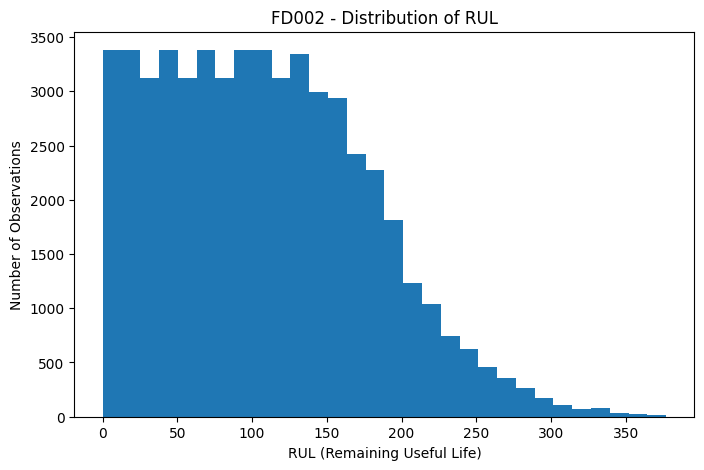

In [149]:
plt.figure(figsize=(8, 5))

plt.hist(train_fd002["RUL"], bins=30)

plt.xlabel("RUL (Remaining Useful Life)")
plt.ylabel("Number of Observations")
plt.title("FD002 - Distribution of RUL")

plt.show()

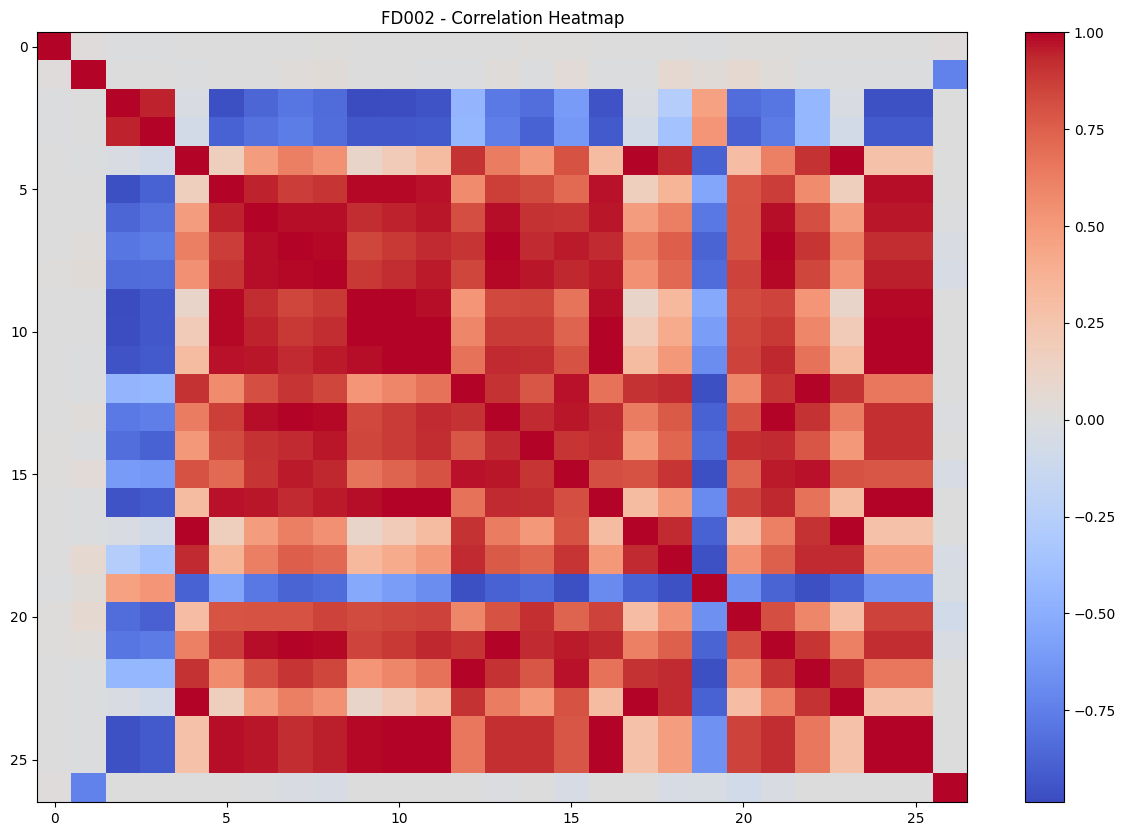

In [150]:
corr_fd002 = train_fd002.corr(numeric_only=True)

plt.figure(figsize=(15, 10))

plt.imshow(corr_fd002, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.title("FD002 - Correlation Heatmap")

plt.show()

In [151]:
train_fd002_clean = train_fd002.copy()

train_fd002_clean.shape

(53759, 27)

In [152]:
X_fd002 = train_fd002_clean.drop(columns=["RUL", "unit_number"])
y_fd002 = train_fd002_clean["RUL"]

print("X_fd002:", X_fd002.shape)
print("y_fd002:", y_fd002.shape)

X_fd002: (53759, 25)
y_fd002: (53759,)


In [153]:
from sklearn.model_selection import GroupShuffleSplit

groups_fd002 = train_fd002_clean["unit_number"]

gss_fd002 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx_fd002, val_idx_fd002 = next(
    gss_fd002.split(X_fd002, y_fd002, groups=groups_fd002)
)

X_train_fd002 = X_fd002.iloc[train_idx_fd002]
X_val_fd002 = X_fd002.iloc[val_idx_fd002]

y_train_fd002 = y_fd002.iloc[train_idx_fd002]
y_val_fd002 = y_fd002.iloc[val_idx_fd002]

print("X_train:", X_train_fd002.shape)
print("X_val:", X_val_fd002.shape)
print("y_train:", y_train_fd002.shape)
print("y_val:", y_val_fd002.shape)

X_train: (43464, 25)
X_val: (10295, 25)
y_train: (43464,)
y_val: (10295,)


In [154]:
from sklearn.tree import DecisionTreeRegressor

dt_fd002 = DecisionTreeRegressor(
    random_state=42
)

dt_fd002.fit(X_train_fd002, y_train_fd002)

print("FD002 Decision Tree trained successfully.")

FD002 Decision Tree trained successfully.


In [155]:
y_pred_dt_fd002 = dt_fd002.predict(X_val_fd002)

print(y_pred_dt_fd002[:10])

[197. 262. 280. 144. 238. 171. 136. 278. 243. 124.]


In [156]:
from sklearn.metrics import mean_absolute_error

mae_dt_fd002 = mean_absolute_error(
    y_val_fd002,
    y_pred_dt_fd002
)

print("FD002 Decision Tree MAE:", mae_dt_fd002)

FD002 Decision Tree MAE: 37.26702282661486


In [157]:
rmse_dt_fd002 = np.sqrt(
    mean_squared_error(y_val_fd002, y_pred_dt_fd002)
)

print("FD002 Decision Tree RMSE:", rmse_dt_fd002)

FD002 Decision Tree RMSE: 52.60713668790807


In [158]:
from sklearn.ensemble import RandomForestRegressor

rf_fd002 = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_fd002.fit(X_train_fd002, y_train_fd002)

print("FD002 Random Forest trained successfully.")


FD002 Random Forest trained successfully.


In [159]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred_rf_fd002 = rf_fd002.predict(X_val_fd002)

mae_rf_fd002 = mean_absolute_error(
    y_val_fd002,
    y_pred_rf_fd002
)

rmse_rf_fd002 = np.sqrt(
    mean_squared_error(y_val_fd002, y_pred_rf_fd002)
)

print("FD002 Random Forest MAE :", mae_rf_fd002)
print("FD002 Random Forest RMSE:", rmse_rf_fd002)

FD002 Random Forest MAE : 26.708481787275378
FD002 Random Forest RMSE: 35.79241284097952


In [160]:
from sklearn.ensemble import GradientBoostingRegressor

gb_fd002 = GradientBoostingRegressor(
    random_state=42
)

gb_fd002.fit(
    X_train_fd002,
    y_train_fd002
)

print("FD002 Gradient Boosting trained successfully.")

FD002 Gradient Boosting trained successfully.


In [161]:
print("FD002 Model Comparison")
print("----------------------")
print("Decision Tree  - MAE :", round(mae_dt_fd002, 2))
print("Decision Tree  - RMSE:", round(rmse_dt_fd002, 2))
print("Random Forest  - MAE :", round(mae_rf_fd002, 2))
print("Random Forest  - RMSE:", round(rmse_rf_fd002, 2))

FD002 Model Comparison
----------------------
Decision Tree  - MAE : 37.27
Decision Tree  - RMSE: 52.61
Random Forest  - MAE : 26.71
Random Forest  - RMSE: 35.79


In [162]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

for n in [50, 100, 150, 200]:
    
    rf_test = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )
    
    rf_test.fit(X_train_fd002, y_train_fd002)
    
    pred = rf_test.predict(X_val_fd002)
    
    mae = mean_absolute_error(y_val_fd002, pred)
    
    print("n_estimators:", n, "MAE:", round(mae, 2))

n_estimators: 50 MAE: 26.85
n_estimators: 100 MAE: 26.71
n_estimators: 150 MAE: 26.64
n_estimators: 200 MAE: 26.61


In [163]:
for depth in [None, 10, 15, 20, 25]:

    rf_test = RandomForestRegressor(
        n_estimators=200,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    rf_test.fit(X_train_fd002, y_train_fd002)

    pred = rf_test.predict(X_val_fd002)

    mae = mean_absolute_error(y_val_fd002, pred)

    print("max_depth:", depth, "MAE:", round(mae, 2))

max_depth: None MAE: 26.61
max_depth: 10 MAE: 26.82
max_depth: 15 MAE: 26.17
max_depth: 20 MAE: 26.41
max_depth: 25 MAE: 26.54


In [164]:
for leaf in [1, 2, 5, 10]:

    rf_test = RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    rf_test.fit(X_train_fd002, y_train_fd002)

    pred = rf_test.predict(X_val_fd002)

    mae = mean_absolute_error(y_val_fd002, pred)

    print("min_samples_leaf:", leaf, "MAE:", round(mae, 2))

min_samples_leaf: 1 MAE: 26.17
min_samples_leaf: 2 MAE: 26.14
min_samples_leaf: 5 MAE: 26.07
min_samples_leaf: 10 MAE: 26.12


In [165]:
rf_fd002_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_fd002_tuned.fit(
    X_train_fd002,
    y_train_fd002
)

y_pred_rf_tuned_fd002 = rf_fd002_tuned.predict(X_val_fd002)

mae_rf_tuned_fd002 = mean_absolute_error(
    y_val_fd002,
    y_pred_rf_tuned_fd002
)

rmse_rf_tuned_fd002 = np.sqrt(
    mean_squared_error(y_val_fd002, y_pred_rf_tuned_fd002)
)

print("Tuned FD002 Random Forest MAE :", round(mae_rf_tuned_fd002, 2))
print("Tuned FD002 Random Forest RMSE:", round(rmse_rf_tuned_fd002, 2))

Tuned FD002 Random Forest MAE : 26.07
Tuned FD002 Random Forest RMSE: 34.96


In [166]:
final_rf_fd002 = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_rf_fd002.fit(
    X_fd002,
    y_fd002
)

print("Final FD002 Random Forest trained on all training data.")

Final FD002 Random Forest trained on all training data.


In [167]:
test_fd002 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\test_FD002.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Test shape:", test_fd002.shape)
print("Number of test engines:", test_fd002["unit_number"].nunique())

Test shape: (33991, 26)
Number of test engines: 259


In [168]:
test_final_fd002 = test_fd002.groupby("unit_number").tail(1)

print("Test final shape:", test_final_fd002.shape)
print("Number of engines:", test_final_fd002["unit_number"].nunique())

Test final shape: (259, 26)
Number of engines: 259


In [169]:
rul_fd002 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\RUL_FD002.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

actual_rul_fd002 = rul_fd002["RUL"].values

print("Number of actual RUL values:", len(actual_rul_fd002))
print(actual_rul_fd002[:10])

Number of actual RUL values: 259
[ 18  79 106 110  15 155   6  90  11  79]


In [170]:
X_test_fd002 = test_final_fd002.drop(
    columns=["unit_number"]
)

print("X_test_fd002 shape:", X_test_fd002.shape)

X_test_fd002 shape: (259, 25)


In [171]:
y_pred_test_fd002 = final_rf_fd002.predict(X_test_fd002)

print("First 10 predicted RUL values:")
print(y_pred_test_fd002[:10])

First 10 predicted RUL values:
[ 18.8409975  150.82457865  87.56924841 106.8430649   13.43093505
 156.04162373  14.4762928   56.77198896  14.35489628 115.07154474]


In [172]:
final_mae_fd002 = mean_absolute_error(
    actual_rul_fd002,
    y_pred_test_fd002
)

final_rmse_fd002 = np.sqrt(
    mean_squared_error(
        actual_rul_fd002,
        y_pred_test_fd002
    )
)

print("FINAL FD002 TEST MAE :", round(final_mae_fd002, 2), "cycles")
print("FINAL FD002 TEST RMSE:", round(final_rmse_fd002, 2), "cycles")

FINAL FD002 TEST MAE : 20.34 cycles
FINAL FD002 TEST RMSE: 28.14 cycles


In [173]:
feature_importance_fd002 = pd.DataFrame({
    "Feature": X_fd002.columns,
    "Importance": final_rf_fd002.feature_importances_
})

feature_importance_fd002 = feature_importance_fd002.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_fd002.head(10)

,Feature,Importance
0,time_cycles,0.693000
14,sensor_11,0.052815
18,sensor_15,0.046695
7,sensor_4,0.043303
16,sensor_13,0.033168
17,sensor_14,0.019467
15,sensor_12,0.015304
5,sensor_2,0.012994
6,sensor_3,0.012716
10,sensor_7,0.012118


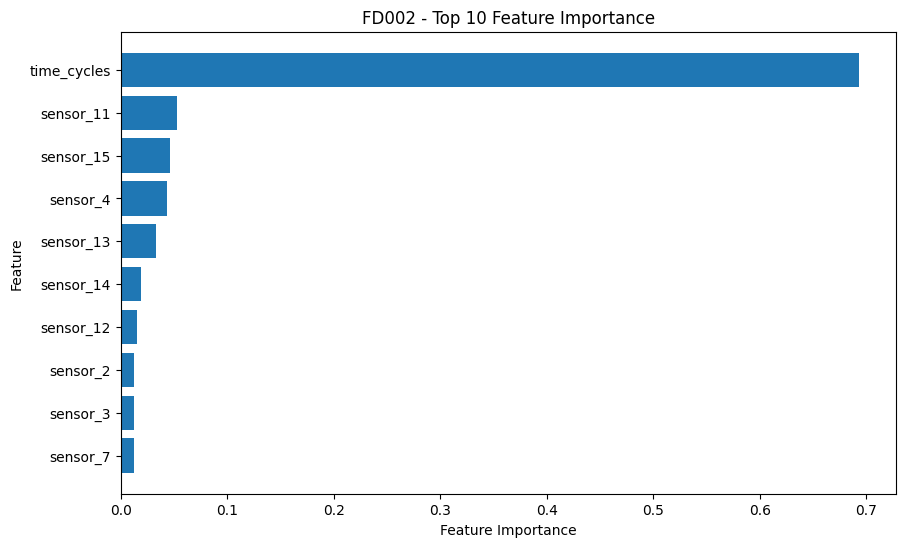

In [174]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_fd002["Feature"].head(10)[::-1],
    feature_importance_fd002["Importance"].head(10)[::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("FD002 - Top 10 Feature Importance")

plt.show()

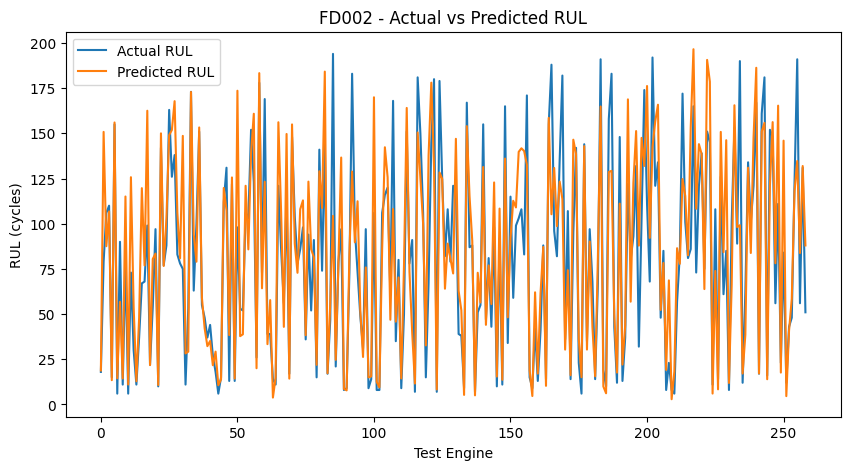

In [175]:
plt.figure(figsize=(10, 5))

plt.plot(
    actual_rul_fd002,
    label="Actual RUL"
)

plt.plot(
    y_pred_test_fd002,
    label="Predicted RUL"
)

plt.xlabel("Test Engine")
plt.ylabel("RUL (cycles)")
plt.title("FD002 - Actual vs Predicted RUL")

plt.legend()
plt.show()

In [176]:
fd002_results = pd.DataFrame({
    "Engine": range(1, len(actual_rul_fd002) + 1),
    "Actual_RUL": actual_rul_fd002,
    "Predicted_RUL": y_pred_test_fd002
})

fd002_results["Absolute_Error"] = abs(
    fd002_results["Actual_RUL"] -
    fd002_results["Predicted_RUL"]
)

fd002_results.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

,Engine,Actual_RUL,Predicted_RUL,Absolute_Error
234,235,190,99.180448,90.819552
85,86,194,104.362461,89.637539
165,166,188,105.238657,82.761343
50,51,98,173.599046,75.599046
30,31,75,148.620660,73.620660
1,2,79,150.824579,71.824579
120,121,67,137.736987,70.736987
169,170,182,113.649403,68.350597
216,217,86,153.339185,67.339185
200,201,111,176.218622,65.218622


In [177]:
print("========== FD002 FINAL RESULTS ==========")
print("Final Model       : Random Forest Regressor")
print("Number of Trees   : 200")
print("Max Depth         : 15")
print("Min Samples Leaf  : 5")
print("Test Engines      : 259")
print("Test MAE          :", round(final_mae_fd002, 2), "cycles")
print("Test RMSE         :", round(final_rmse_fd002, 2), "cycles")

========== FD002 FINAL RESULTS ==========
Final Model       : Random Forest Regressor
Number of Trees   : 200
Max Depth         : 15
Min Samples Leaf  : 5
Test Engines      : 259
Test MAE          : 20.34 cycles
Test RMSE         : 28.14 cycles


In [178]:
train_fd003 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\train_FD003.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("FD003 train shape:", train_fd003.shape)
print("Number of engines:", train_fd003["unit_number"].nunique())

FD003 train shape: (24720, 26)
Number of engines: 100


In [179]:
train_fd003.isnull().sum()

unit_number              0
time_cycles              0
operational_setting_1    0
operational_setting_2    0
operational_setting_3    0
sensor_1                 0
sensor_2                 0
sensor_3                 0
sensor_4                 0
sensor_5                 0
sensor_6                 0
sensor_7                 0
sensor_8                 0
sensor_9                 0
sensor_10                0
sensor_11                0
sensor_12                0
sensor_13                0
sensor_14                0
sensor_15                0
sensor_16                0
sensor_17                0
sensor_18                0
sensor_19                0
sensor_20                0
sensor_21                0
dtype: int64

In [180]:
train_fd003.groupby("unit_number")["time_cycles"].max()

unit_number
1      259
2      253
3      222
4      272
5      213
      ... 
96     491
97     275
98     307
99     145
100    152
Name: time_cycles, Length: 100, dtype: int64

In [181]:
max_cycles_fd003 = train_fd003.groupby("unit_number")["time_cycles"].max()

train_fd003["RUL"] = (
    train_fd003["unit_number"].map(max_cycles_fd003)
    - train_fd003["time_cycles"]
)

In [182]:
train_fd003[["unit_number", "time_cycles", "RUL"]].head(10)

,unit_number,time_cycles,RUL
0,1,1,258
1,1,2,257
2,1,3,256
3,1,4,255
4,1,5,254
5,1,6,253
6,1,7,252
7,1,8,251
8,1,9,250
9,1,10,249


In [183]:
train_fd003["RUL"].describe()

count    24720.000000
mean       138.077063
std         98.846675
min          0.000000
25%         61.000000
50%        123.000000
75%        190.000000
max        524.000000
Name: RUL, dtype: float64

In [184]:
constant_cols_fd003 = [
    col for col in train_fd003.columns
    if train_fd003[col].nunique() == 1
]

constant_cols_fd003

['operational_setting_3',
 'sensor_1',
 'sensor_5',
 'sensor_16',
 'sensor_18',
 'sensor_19']

In [185]:
train_fd003_clean = train_fd003.drop(columns=constant_cols_fd003)

print("Original shape:", train_fd003.shape)
print("Cleaned shape:", train_fd003_clean.shape)

Original shape: (24720, 27)
Cleaned shape: (24720, 21)


In [186]:
correlation_fd003 = train_fd003_clean.corr(numeric_only=True)["RUL"].sort_values()

correlation_fd003

sensor_11               -0.688915
sensor_4                -0.657224
sensor_13               -0.656340
sensor_8                -0.655345
sensor_17               -0.649220
sensor_3                -0.624236
sensor_2                -0.590564
sensor_9                -0.551843
time_cycles             -0.482744
sensor_14               -0.481807
sensor_10               -0.363432
sensor_12               -0.329452
sensor_7                -0.315048
sensor_6                -0.215352
unit_number             -0.077196
sensor_15               -0.016501
operational_setting_2   -0.001204
operational_setting_1    0.003700
sensor_21                0.033465
sensor_20                0.037782
RUL                      1.000000
Name: RUL, dtype: float64

In [187]:
X_fd003 = train_fd003_clean.drop(columns=["RUL", "unit_number"])
y_fd003 = train_fd003_clean["RUL"]

print("X shape:", X_fd003.shape)
print("y shape:", y_fd003.shape)

X shape: (24720, 19)
y shape: (24720,)


In [188]:
from sklearn.model_selection import GroupShuffleSplit

groups_fd003 = train_fd003_clean["unit_number"]

gss_fd003 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx_fd003, val_idx_fd003 = next(
    gss_fd003.split(X_fd003, y_fd003, groups=groups_fd003)
)

X_train_fd003 = X_fd003.iloc[train_idx_fd003]
X_val_fd003 = X_fd003.iloc[val_idx_fd003]

y_train_fd003 = y_fd003.iloc[train_idx_fd003]
y_val_fd003 = y_fd003.iloc[val_idx_fd003]

print("X_train:", X_train_fd003.shape)
print("X_val:", X_val_fd003.shape)
print("y_train:", y_train_fd003.shape)
print("y_val:", y_val_fd003.shape)

X_train: (20012, 19)
X_val: (4708, 19)
y_train: (20012,)
y_val: (4708,)


In [189]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

dt_fd003 = DecisionTreeRegressor(random_state=42)

dt_fd003.fit(X_train_fd003, y_train_fd003)

y_pred_dt_fd003 = dt_fd003.predict(X_val_fd003)

mae_dt_fd003 = mean_absolute_error(y_val_fd003, y_pred_dt_fd003)
rmse_dt_fd003 = np.sqrt(mean_squared_error(y_val_fd003, y_pred_dt_fd003))

print("FD003 Decision Tree MAE:", mae_dt_fd003)
print("FD003 Decision Tree RMSE:", rmse_dt_fd003)

FD003 Decision Tree MAE: 50.594944774851314
FD003 Decision Tree RMSE: 76.4006023476413


In [190]:
from sklearn.ensemble import RandomForestRegressor

rf_fd003 = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_fd003.fit(X_train_fd003, y_train_fd003)

y_pred_rf_fd003 = rf_fd003.predict(X_val_fd003)

mae_rf_fd003 = mean_absolute_error(y_val_fd003, y_pred_rf_fd003)
rmse_rf_fd003 = np.sqrt(mean_squared_error(y_val_fd003, y_pred_rf_fd003))

print("FD003 Random Forest MAE:", mae_rf_fd003)
print("FD003 Random Forest RMSE:", rmse_rf_fd003)

FD003 Random Forest MAE: 36.91938190314359
FD003 Random Forest RMSE: 58.15859100739259


In [191]:
from sklearn.ensemble import GradientBoostingRegressor

gb_fd003 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

gb_fd003.fit(X_train_fd003, y_train_fd003)

y_pred_gb_fd003 = gb_fd003.predict(X_val_fd003)

mae_gb_fd003 = mean_absolute_error(y_val_fd003, y_pred_gb_fd003)
rmse_gb_fd003 = np.sqrt(mean_squared_error(y_val_fd003, y_pred_gb_fd003))

print("FD003 Gradient Boosting MAE:", mae_gb_fd003)
print("FD003 Gradient Boosting RMSE:", rmse_gb_fd003)

FD003 Gradient Boosting MAE: 35.04789833501577
FD003 Gradient Boosting RMSE: 53.547647125026685


In [192]:
feature_importance_fd003 = pd.Series(
    gb_fd003.feature_importances_,
    index=X_fd003.columns
).sort_values(ascending=False)

feature_importance_fd003

sensor_11                0.354780
time_cycles              0.180481
sensor_4                 0.145129
sensor_12                0.100491
sensor_6                 0.049159
sensor_9                 0.041223
sensor_7                 0.033481
sensor_17                0.021929
sensor_3                 0.021529
sensor_14                0.018976
sensor_13                0.013950
sensor_8                 0.011179
sensor_2                 0.006593
sensor_15                0.000659
sensor_21                0.000378
operational_setting_1    0.000062
sensor_10                0.000000
operational_setting_2    0.000000
sensor_20                0.000000
dtype: float64

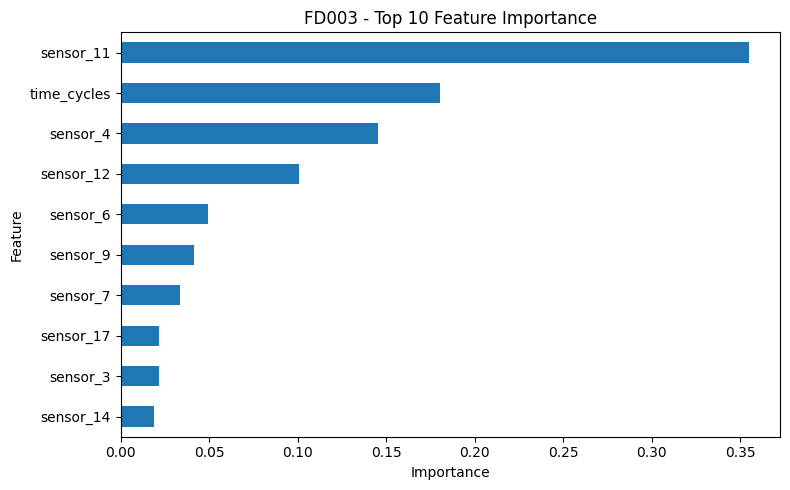

In [193]:
import matplotlib.pyplot as plt

feature_importance_fd003.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("FD003 - Top 10 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [194]:
final_gb_fd003 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

final_gb_fd003.fit(X_fd003, y_fd003)

print("Final FD003 model trained successfully.")

Final FD003 model trained successfully.


In [195]:
test_fd003 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\test_FD003.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("FD003 test shape:", test_fd003.shape)
print("Number of engines:", test_fd003["unit_number"].nunique())

FD003 test shape: (16596, 26)
Number of engines: 100


In [196]:
test_final_fd003 = test_fd003.groupby("unit_number").tail(1)

print("Test final shape:", test_final_fd003.shape)
print("Number of engines:", test_final_fd003["unit_number"].nunique())

Test final shape: (100, 26)
Number of engines: 100


In [197]:
actual_rul_fd003 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\RUL_FD003.txt",
    header=None
).iloc[:, 0]

print("Number of actual RUL values:", len(actual_rul_fd003))
print(actual_rul_fd003.head(10).to_list())

Number of actual RUL values: 100
[44, 51, 27, 120, 101, 99, 71, 55, 55, 66]


In [198]:
X_test_fd003 = test_final_fd003.drop(
    columns=["unit_number"] + constant_cols_fd003
)

print("X_test shape:", X_test_fd003.shape)

X_test shape: (100, 19)


In [199]:
y_pred_fd003 = final_gb_fd003.predict(X_test_fd003)

print("Number of predictions:", len(y_pred_fd003))
print("First 10 predictions:", y_pred_fd003[:10])

Number of predictions: 100
First 10 predictions: [ 49.39203882  73.12711254  39.95116417 160.24584031 190.79127939
 122.51239714  62.31122979  56.43755458  62.4556667   94.43564236]


In [200]:
mae_fd003 = mean_absolute_error(actual_rul_fd003, y_pred_fd003)
rmse_fd003 = np.sqrt(mean_squared_error(actual_rul_fd003, y_pred_fd003))

print("FD003 Test MAE:", mae_fd003)
print("FD003 Test RMSE:", rmse_fd003)

FD003 Test MAE: 28.378128716824087
FD003 Test RMSE: 38.84705671017006


In [201]:
fd003_results = pd.DataFrame({
    "engine": test_final_fd003["unit_number"].values,
    "actual_rul": actual_rul_fd003.values,
    "predicted_rul": y_pred_fd003
})

fd003_results["error"] = (
    fd003_results["predicted_rul"] - fd003_results["actual_rul"]
)

fd003_results["absolute_error"] = fd003_results["error"].abs()

fd003_results.sort_values(
    "absolute_error",
    ascending=False
).head(10)

,engine,actual_rul,predicted_rul,error,absolute_error
79,80,133,250.987392,117.987392,117.987392
15,16,56,154.561111,98.561111,98.561111
60,61,129,221.342962,92.342962,92.342962
4,5,101,190.791279,89.791279,89.791279
90,91,81,167.208257,86.208257,86.208257
73,74,117,202.113305,85.113305,85.113305
53,54,87,167.785096,80.785096,80.785096
64,65,115,195.214941,80.214941,80.214941
92,93,67,140.858741,73.858741,73.858741
67,68,103,176.411671,73.411671,73.411671


In [202]:
GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

GradientBoostingRegressor(learning_rate=0.05, min_samples_leaf=2,
                          random_state=42)

In [203]:
n_estimators=100
learning_rate=0.05
max_depth=3
min_samples_leaf=2

In [204]:
n_estimators_values = [50, 100, 150, 200]

for n in n_estimators_values:
    model = GradientBoostingRegressor(
        n_estimators=n,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )

    model.fit(X_train_fd003, y_train_fd003)

    pred = model.predict(X_val_fd003)

    mae = mean_absolute_error(y_val_fd003, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd003, pred))

    print(
        "n_estimators:", n,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

n_estimators: 50 | MAE: 36.037515366091334 | RMSE: 53.163713147383596
n_estimators: 100 | MAE: 35.04789833501577 | RMSE: 53.547647125026685
n_estimators: 150 | MAE: 35.42039090796916 | RMSE: 54.30460968505099
n_estimators: 200 | MAE: 35.67493455541528 | RMSE: 54.9663818026423


In [205]:
learning_rate_values = [0.01, 0.03, 0.05, 0.1, 0.2]

for lr in learning_rate_values:
    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=lr,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )

    model.fit(X_train_fd003, y_train_fd003)

    pred = model.predict(X_val_fd003)

    mae = mean_absolute_error(y_val_fd003, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd003, pred))

    print(
        "learning_rate:", lr,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

learning_rate: 0.01 | MAE: 45.93074737595237 | RMSE: 62.3166517238286
learning_rate: 0.03 | MAE: 35.325483535037854 | RMSE: 52.826613939282424
learning_rate: 0.05 | MAE: 35.04789833501577 | RMSE: 53.547647125026685
learning_rate: 0.1 | MAE: 35.701707860587454 | RMSE: 54.80424516052293
learning_rate: 0.2 | MAE: 36.25908695954636 | RMSE: 56.585230932487896


In [206]:
max_depth_values = [2, 3, 4, 5, 6]

for depth in max_depth_values:
    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=depth,
        min_samples_leaf=2,
        random_state=42
    )

    model.fit(X_train_fd003, y_train_fd003)

    pred = model.predict(X_val_fd003)

    mae = mean_absolute_error(y_val_fd003, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd003, pred))

    print(
        "max_depth:", depth,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

max_depth: 2 | MAE: 34.54828034914502 | RMSE: 52.48620920552609
max_depth: 3 | MAE: 35.04789833501577 | RMSE: 53.547647125026685
max_depth: 4 | MAE: 35.41965421634693 | RMSE: 54.520048498118015
max_depth: 5 | MAE: 35.22445596336094 | RMSE: 55.01584115294163
max_depth: 6 | MAE: 35.64733331602788 | RMSE: 56.31836857492616


In [207]:
min_samples_leaf_values = [1, 2, 5, 10, 20]

for leaf in min_samples_leaf_values:
    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train_fd003, y_train_fd003)

    pred = model.predict(X_val_fd003)

    mae = mean_absolute_error(y_val_fd003, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd003, pred))

    print(
        "min_samples_leaf:", leaf,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

min_samples_leaf: 1 | MAE: 34.54828034914502 | RMSE: 52.48620920552609
min_samples_leaf: 2 | MAE: 34.54828034914502 | RMSE: 52.48620920552609
min_samples_leaf: 5 | MAE: 34.54828034914502 | RMSE: 52.48620920552609
min_samples_leaf: 10 | MAE: 34.54828034914502 | RMSE: 52.48620920552609
min_samples_leaf: 20 | MAE: 34.54828034914502 | RMSE: 52.48620920552609


In [208]:
final_gb_fd003_tuned = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=2,
    random_state=42
)

final_gb_fd003_tuned.fit(X_fd003, y_fd003)

GradientBoostingRegressor(learning_rate=0.05, max_depth=2, min_samples_leaf=2,
                          random_state=42)

In [209]:
X_test_fd003 = test_final_fd003.drop(
    columns=["unit_number"] + constant_cols_fd003
)

print("X_test shape:", X_test_fd003.shape)
print("Actual RUL shape:", actual_rul_fd003.shape)

X_test shape: (100, 19)
Actual RUL shape: (100,)


In [210]:
y_pred_test_fd003 = final_gb_fd003_tuned.predict(X_test_fd003)

print("First 10 predictions:")
print(y_pred_test_fd003[:10])

First 10 predictions:
[ 45.1293287   68.46112423  39.25426651 163.23326524 201.33518387
 137.63826318  55.31967596  51.15988044  67.75109015 101.39025851]


In [211]:
mae_fd003 = mean_absolute_error(
    actual_rul_fd003,
    y_pred_test_fd003
)

rmse_fd003 = np.sqrt(
    mean_squared_error(
        actual_rul_fd003,
        y_pred_test_fd003
    )
)

print("FD003 Test MAE:", mae_fd003)
print("FD003 Test RMSE:", rmse_fd003)

FD003 Test MAE: 32.251550560429294
FD003 Test RMSE: 42.49625432853578


In [212]:
final_gb_fd003_tuned = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=2,
    random_state=42
)

final_gb_fd003_tuned.fit(X_fd003, y_fd003)

print("Tuned FD003 model trained successfully.")

Tuned FD003 model trained successfully.


In [213]:
feature_importance_fd003 = pd.Series(
    final_gb_fd003_tuned.feature_importances_,
    index=X_fd003.columns
).sort_values(ascending=False)

print(feature_importance_fd003)

sensor_11                0.345895
time_cycles              0.189162
sensor_4                 0.121323
sensor_12                0.069332
sensor_13                0.065816
sensor_9                 0.048697
sensor_6                 0.046596
sensor_8                 0.030875
sensor_17                0.027997
sensor_3                 0.022280
sensor_14                0.015979
sensor_7                 0.010182
sensor_2                 0.005865
operational_setting_1    0.000000
sensor_10                0.000000
operational_setting_2    0.000000
sensor_15                0.000000
sensor_20                0.000000
sensor_21                0.000000
dtype: float64


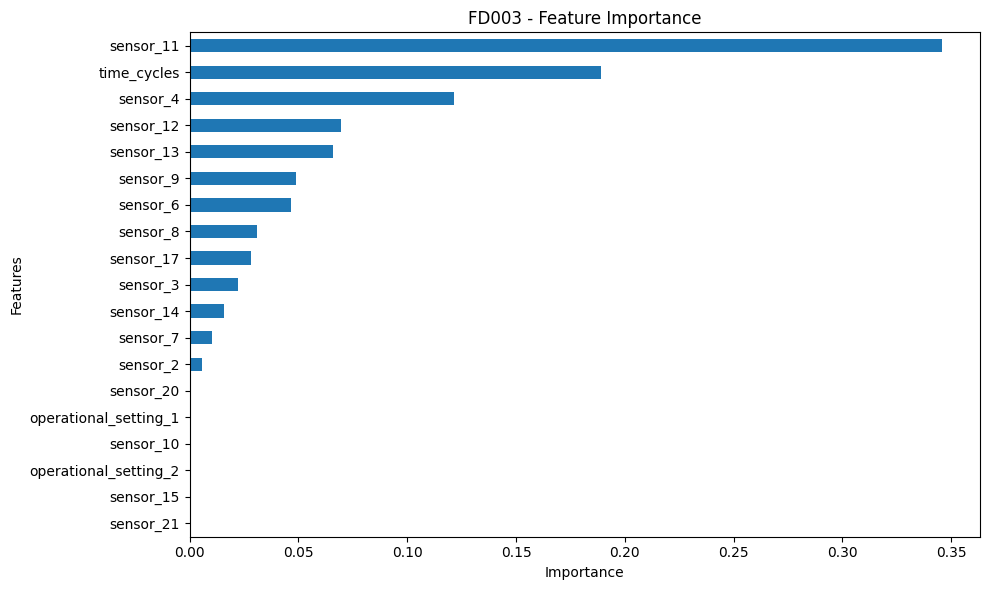

In [214]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

feature_importance_fd003.sort_values().plot(kind="barh")

plt.title("FD003 - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

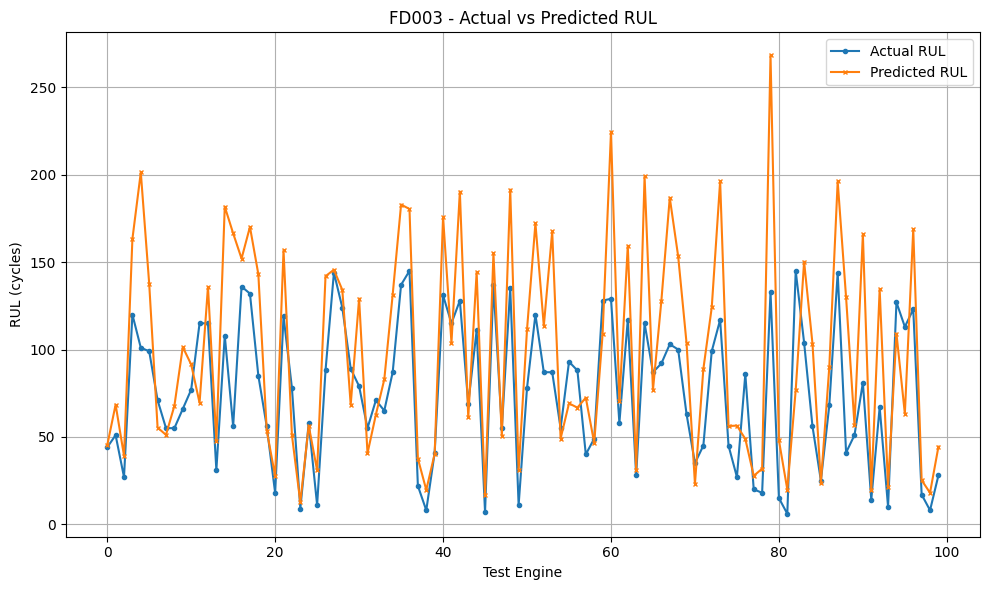

In [215]:
plt.figure(figsize=(10, 6))

plt.plot(
    actual_rul_fd003,
    label="Actual RUL",
    marker="o",
    markersize=3
)

plt.plot(
    y_pred_test_fd003,
    label="Predicted RUL",
    marker="x",
    markersize=3
)

plt.xlabel("Test Engine")
plt.ylabel("RUL (cycles)")
plt.title("FD003 - Actual vs Predicted RUL")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [216]:
error_fd003 = pd.DataFrame({
    "actual_rul": actual_rul_fd003,
    "predicted_rul": y_pred_test_fd003
})

error_fd003["error"] = (
    error_fd003["predicted_rul"]
    - error_fd003["actual_rul"]
)

error_fd003["absolute_error"] = (
    error_fd003["error"].abs()
)

error_fd003["engine"] = range(1, len(error_fd003) + 1)

top_errors_fd003 = error_fd003.sort_values(
    "absolute_error",
    ascending=False
).head(10)

print(top_errors_fd003)

    actual_rul  predicted_rul       error  absolute_error  engine
79         133     268.357609  135.357609      135.357609      80
15          56     166.452261  110.452261      110.452261      16
4          101     201.335184  100.335184      100.335184       5
60         129     224.437692   95.437692       95.437692      61
88          41     129.808647   88.808647       88.808647      89
90          81     165.951692   84.951692       84.951692      91
64         115     199.105237   84.105237       84.105237      65
67         103     186.850058   83.850058       83.850058      68
53          87     167.525491   80.525491       80.525491      54
73         117     196.300037   79.300037       79.300037      74


In [217]:
train_fd004 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\train_FD004.txt",
    sep=r"\s+",
    header=None
)

train_fd004.columns = columns

print("Shape:", train_fd004.shape)
print("Number of engines:", train_fd004["unit_number"].nunique())
print("Missing values:", train_fd004.isnull().sum().sum())

Shape: (61249, 26)
Number of engines: 249
Missing values: 0


In [218]:
max_cycles_fd004 = train_fd004.groupby("unit_number")["time_cycles"].max()

train_fd004["RUL"] = (
    train_fd004["unit_number"].map(max_cycles_fd004)
    - train_fd004["time_cycles"]
)

print(train_fd004["RUL"].describe())

count    61249.000000
mean       133.311417
std         89.783389
min          0.000000
25%         61.000000
50%        122.000000
75%        190.000000
max        542.000000
Name: RUL, dtype: float64


In [219]:
constant_cols_fd004 = [
    col for col in train_fd004.columns
    if train_fd004[col].nunique() == 1
]

print("Constant columns:")
print(constant_cols_fd004)

Constant columns:
[]


In [220]:
train_fd004_clean = train_fd004.copy()

X_fd004 = train_fd004_clean.drop(
    columns=["RUL", "unit_number"]
)

y_fd004 = train_fd004_clean["RUL"]

print("X_fd004 shape:", X_fd004.shape)
print("y_fd004 shape:", y_fd004.shape)

X_fd004 shape: (61249, 25)
y_fd004 shape: (61249,)


In [221]:
correlation_fd004 = train_fd004_clean.corr(numeric_only=True)["RUL"] \
    .sort_values(ascending=False)

print(correlation_fd004)

RUL                      1.000000
sensor_20                0.002812
sensor_21                0.002791
sensor_18                0.002765
operational_setting_3    0.002303
sensor_19                0.002303
sensor_8                 0.002086
sensor_1                 0.001889
sensor_5                 0.001679
sensor_13                0.001501
sensor_6                 0.001349
sensor_7                -0.001429
sensor_12               -0.001639
operational_setting_2   -0.002280
operational_setting_1   -0.002380
unit_number             -0.003656
sensor_15               -0.003957
sensor_2                -0.004443
sensor_10               -0.008924
sensor_9                -0.024727
sensor_3                -0.032924
sensor_17               -0.032939
sensor_4                -0.045881
sensor_16               -0.053804
sensor_11               -0.056639
sensor_14               -0.078126
time_cycles             -0.610620
Name: RUL, dtype: float64


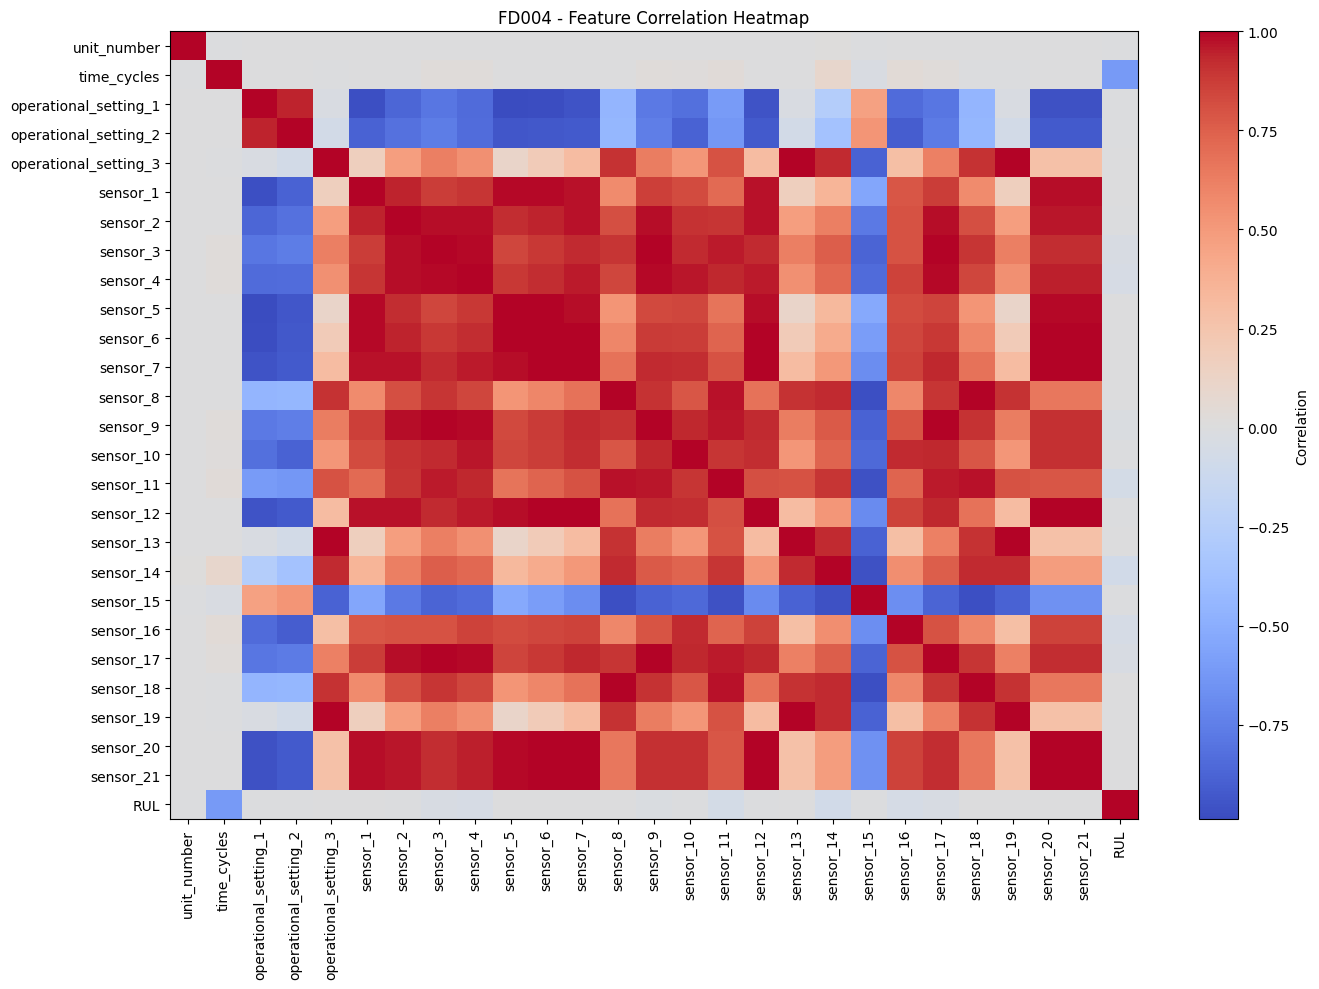

In [222]:
corr_fd004 = train_fd004_clean.corr(numeric_only=True)

plt.figure(figsize=(14, 10))

plt.imshow(corr_fd004, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr_fd004.columns)),
    corr_fd004.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_fd004.columns)),
    corr_fd004.columns
)

plt.title("FD004 - Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [223]:
from sklearn.model_selection import GroupShuffleSplit

groups_fd004 = train_fd004_clean["unit_number"]

gss_fd004 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx_fd004, val_idx_fd004 = next(
    gss_fd004.split(
        X_fd004,
        y_fd004,
        groups=groups_fd004
    )
)

X_train_fd004 = X_fd004.iloc[train_idx_fd004]
X_val_fd004 = X_fd004.iloc[val_idx_fd004]

y_train_fd004 = y_fd004.iloc[train_idx_fd004]
y_val_fd004 = y_fd004.iloc[val_idx_fd004]

print("X_train:", X_train_fd004.shape)
print("X_val:", X_val_fd004.shape)
print("y_train:", y_train_fd004.shape)
print("y_val:", y_val_fd004.shape)

X_train: (49294, 25)
X_val: (11955, 25)
y_train: (49294,)
y_val: (11955,)


In [224]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

dt_fd004 = DecisionTreeRegressor(
    random_state=42
)

dt_fd004.fit(X_train_fd004, y_train_fd004)

y_pred_dt_fd004 = dt_fd004.predict(X_val_fd004)

mae_dt_fd004 = mean_absolute_error(
    y_val_fd004,
    y_pred_dt_fd004
)

rmse_dt_fd004 = np.sqrt(
    mean_squared_error(
        y_val_fd004,
        y_pred_dt_fd004
    )
)

print("FD004 Decision Tree")
print("MAE:", mae_dt_fd004)
print("RMSE:", rmse_dt_fd004)

FD004 Decision Tree
MAE: 51.89937264742785
RMSE: 73.26114179790275


In [225]:
from sklearn.ensemble import RandomForestRegressor

rf_fd004 = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_fd004.fit(X_train_fd004, y_train_fd004)

y_pred_rf_fd004 = rf_fd004.predict(X_val_fd004)

mae_rf_fd004 = mean_absolute_error(
    y_val_fd004,
    y_pred_rf_fd004
)

rmse_rf_fd004 = np.sqrt(
    mean_squared_error(
        y_val_fd004,
        y_pred_rf_fd004
    )
)

print("FD004 Random Forest")
print("MAE:", mae_rf_fd004)
print("RMSE:", rmse_rf_fd004)

FD004 Random Forest
MAE: 41.19341112505228
RMSE: 56.194445171480154


In [226]:
from sklearn.ensemble import GradientBoostingRegressor

gb_fd004 = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

gb_fd004.fit(X_train_fd004, y_train_fd004)

y_pred_gb_fd004 = gb_fd004.predict(X_val_fd004)

mae_gb_fd004 = mean_absolute_error(
    y_val_fd004,
    y_pred_gb_fd004
)

rmse_gb_fd004 = np.sqrt(
    mean_squared_error(
        y_val_fd004,
        y_pred_gb_fd004
    )
)

print("FD004 Gradient Boosting")
print("MAE:", mae_gb_fd004)
print("RMSE:", rmse_gb_fd004)

FD004 Gradient Boosting
MAE: 45.12477147059219
RMSE: 58.13669352336815


In [227]:
n_estimators_values_fd004 = [50, 100, 150, 200]

for n in n_estimators_values_fd004:
    model = RandomForestRegressor(
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_fd004, y_train_fd004)

    pred = model.predict(X_val_fd004)

    mae = mean_absolute_error(y_val_fd004, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd004, pred))

    print(
        "n_estimators:", n,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

n_estimators: 50 | MAE: 41.301619406106234 | RMSE: 56.35110493729206
n_estimators: 100 | MAE: 41.19341112505228 | RMSE: 56.194445171480154
n_estimators: 150 | MAE: 41.16274362191552 | RMSE: 56.12961333940173
n_estimators: 200 | MAE: 41.14253366792136 | RMSE: 56.093201456656466


In [228]:
max_depth_values_fd004 = [None, 10, 15, 20, 25]

for depth in max_depth_values_fd004:
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_fd004, y_train_fd004)

    pred = model.predict(X_val_fd004)

    mae = mean_absolute_error(y_val_fd004, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd004, pred))

    print(
        "max_depth:", depth,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

max_depth: None | MAE: 41.14253366792136 | RMSE: 56.093201456656466
max_depth: 10 | MAE: 41.661022778450864 | RMSE: 55.985383034573026
max_depth: 15 | MAE: 41.00239263769008 | RMSE: 55.76111603003543
max_depth: 20 | MAE: 41.08033215934931 | RMSE: 55.989889346732454
max_depth: 25 | MAE: 41.14023816032055 | RMSE: 56.07584410991799


In [229]:
min_samples_leaf_values_fd004 = [1, 2, 5, 10]

for leaf in min_samples_leaf_values_fd004:
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_fd004, y_train_fd004)

    pred = model.predict(X_val_fd004)

    mae = mean_absolute_error(y_val_fd004, pred)
    rmse = np.sqrt(mean_squared_error(y_val_fd004, pred))

    print(
        "min_samples_leaf:", leaf,
        "| MAE:", mae,
        "| RMSE:", rmse
    )

min_samples_leaf: 1 | MAE: 41.00239263769009 | RMSE: 55.76111603003543
min_samples_leaf: 2 | MAE: 40.96649641244298 | RMSE: 55.75043727134477
min_samples_leaf: 5 | MAE: 40.955141762468074 | RMSE: 55.77598786841667
min_samples_leaf: 10 | MAE: 40.96716659215069 | RMSE: 55.734926505727344


In [230]:
final_rf_fd004 = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_rf_fd004.fit(X_fd004, y_fd004)

print("Final FD004 model trained successfully.")

Final FD004 model trained successfully.


In [231]:
test_fd004 = pd.read_csv(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\test_FD004.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Test shape:", test_fd004.shape)
print("Number of engines:", test_fd004["unit_number"].nunique())

Test shape: (41214, 26)
Number of engines: 248


In [232]:
test_final_fd004 = test_fd004.groupby("unit_number").tail(1)

print("Test final shape:", test_final_fd004.shape)
print("Number of engines:", test_final_fd004["unit_number"].nunique())

Test final shape: (248, 26)
Number of engines: 248


In [233]:
X_test_fd004 = test_final_fd004.drop(columns=["unit_number"])

print("X_test_fd004 shape:", X_test_fd004.shape)

X_test_fd004 shape: (248, 25)


In [234]:
actual_rul_fd004 = np.loadtxt(
    r"C:\Users\akhil\Downloads\ML\ML_VSCode\turbofan_engine_project\CMAPSSData\RUL_FD004.txt"
)

print("Number of actual RUL values:", len(actual_rul_fd004))
print("First 10 actual RUL values:", actual_rul_fd004[:10])

Number of actual RUL values: 248
First 10 actual RUL values: [ 22.  39. 107.  75. 149.  78.  94.  14.  99. 162.]


In [235]:
y_pred_fd004 = final_rf_fd004.predict(X_test_fd004)

print("Number of predictions:", len(y_pred_fd004))
print("First 10 predictions:", y_pred_fd004[:10])

Number of predictions: 248
First 10 predictions: [ 47.75990313  58.85355188  92.93824906 116.15465014 155.69736603
 165.46030936 143.58185923  17.06197406  84.26835267 268.68545093]


In [236]:
mae_fd004 = mean_absolute_error(
    actual_rul_fd004,
    y_pred_fd004
)

rmse_fd004 = np.sqrt(
    mean_squared_error(
        actual_rul_fd004,
        y_pred_fd004
    )
)

print("FD004 Test MAE:", mae_fd004)
print("FD004 Test RMSE:", rmse_fd004)

FD004 Test MAE: 27.964312087190073
FD004 Test RMSE: 39.41820131070164


In [237]:
feature_importance_fd004 = pd.Series(
    final_rf_fd004.feature_importances_,
    index=X_fd004.columns
).sort_values(ascending=False)

print(feature_importance_fd004.head(10))

time_cycles    0.466351
sensor_13      0.142494
sensor_11      0.080048
sensor_15      0.075611
sensor_6       0.039467
sensor_4       0.033153
sensor_2       0.021448
sensor_14      0.019637
sensor_9       0.019226
sensor_8       0.019058
dtype: float64


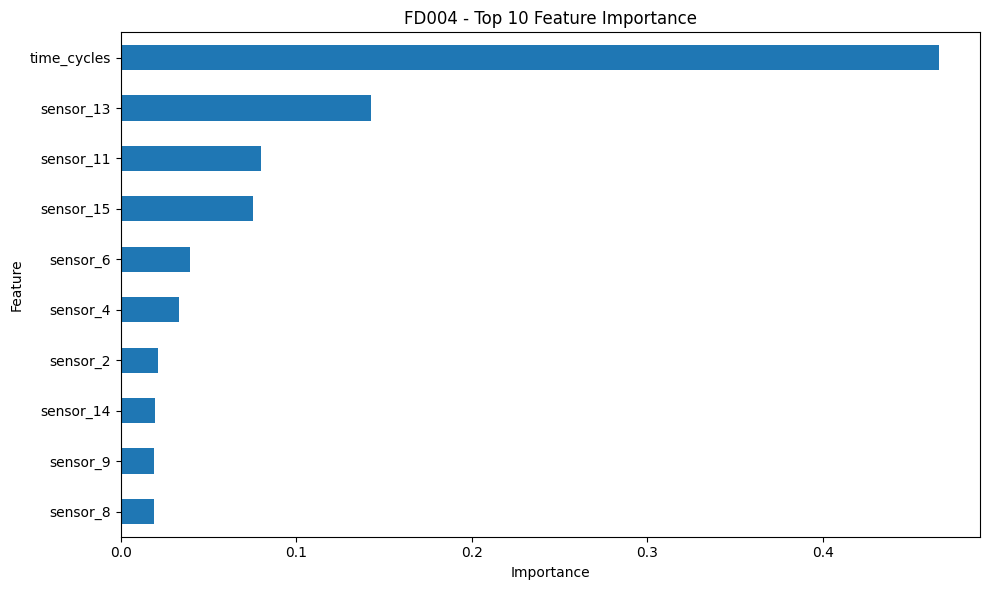

In [238]:
plt.figure(figsize=(10, 6))

feature_importance_fd004.head(10).sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("FD004 - Top 10 Feature Importance")
plt.tight_layout()
plt.show()

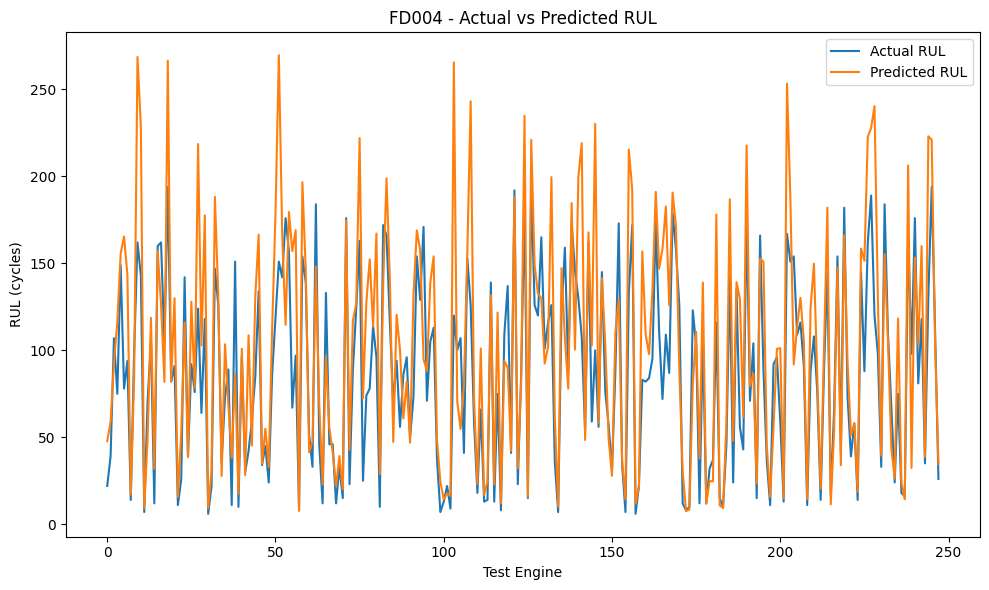

In [239]:
plt.figure(figsize=(10, 6))

plt.plot(
    actual_rul_fd004,
    label="Actual RUL"
)

plt.plot(
    y_pred_fd004,
    label="Predicted RUL"
)

plt.xlabel("Test Engine")
plt.ylabel("RUL (cycles)")
plt.title("FD004 - Actual vs Predicted RUL")
plt.legend()
plt.tight_layout()
plt.show()

In [240]:
error_fd004 = actual_rul_fd004 - y_pred_fd004

error_df_fd004 = pd.DataFrame({
    "Engine": test_final_fd004["unit_number"].values,
    "Actual_RUL": actual_rul_fd004,
    "Predicted_RUL": y_pred_fd004,
    "Error": error_fd004,
    "Absolute_Error": np.abs(error_fd004)
})

largest_errors_fd004 = error_df_fd004.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

print(largest_errors_fd004)

     Engine  Actual_RUL  Predicted_RUL       Error  Absolute_Error
103     104       120.0     265.568834 -145.568834      145.568834
145     146       100.0     230.286343 -130.286343      130.286343
228     229       120.0     240.401878 -120.401878      120.401878
51       52       151.0     269.673985 -118.673985      118.673985
108     109       126.0     243.225255 -117.225255      117.225255
141     142       108.0     219.149647 -111.149647      111.149647
9        10       162.0     268.685451 -106.685451      106.685451
27       28       124.0     218.640862  -94.640862       94.640862
244     245       131.0     223.085554  -92.085554       92.085554
55       56        67.0     157.052943  -90.052943       90.052943


In [241]:
results_summary = pd.DataFrame({
    "Dataset": ["FD001", "FD002", "FD003", "FD004"],
    "Model": [
        "Gradient Boosting",
        "Random Forest",
        "Gradient Boosting",
        "Random Forest"
    ],
    "Test Engines": [100, 259, 100, 248],
    "Test MAE": [
        18.18,
        20.34,
        32.25,
        27.96
    ],
    "Test RMSE": [
        24.86,
        28.14,
        42.50,
        39.42
    ]
})

print(results_summary)

  Dataset              Model  Test Engines  Test MAE  Test RMSE
0   FD001  Gradient Boosting           100     18.18      24.86
1   FD002      Random Forest           259     20.34      28.14
2   FD003  Gradient Boosting           100     32.25      42.50
3   FD004      Random Forest           248     27.96      39.42


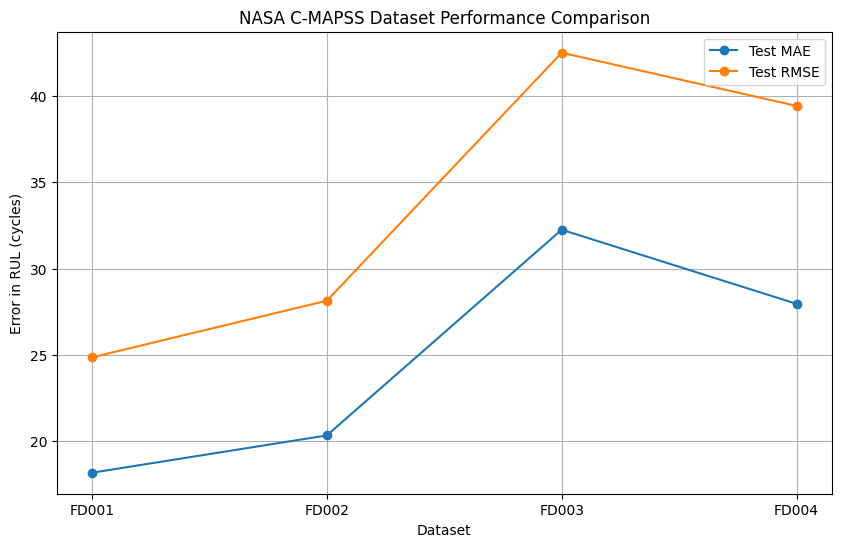

In [242]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    results_summary["Dataset"],
    results_summary["Test MAE"],
    marker="o",
    label="Test MAE"
)

plt.plot(
    results_summary["Dataset"],
    results_summary["Test RMSE"],
    marker="o",
    label="Test RMSE"
)

plt.xlabel("Dataset")
plt.ylabel("Error in RUL (cycles)")
plt.title("NASA C-MAPSS Dataset Performance Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [243]:
print("FINAL PROJECT SUMMARY")
print("=" * 50)

print("Project: AI-Based Predictive Maintenance and RUL Prediction")
print("Dataset: NASA C-MAPSS Turbofan Engine Degradation Dataset")
print()

for _, row in results_summary.iterrows():
    print(
        f"{row['Dataset']}: "
        f"{row['Model']} | "
        f"MAE = {row['Test MAE']} cycles | "
        f"RMSE = {row['Test RMSE']} cycles"
    )

FINAL PROJECT SUMMARY
Project: AI-Based Predictive Maintenance and RUL Prediction
Dataset: NASA C-MAPSS Turbofan Engine Degradation Dataset

FD001: Gradient Boosting | MAE = 18.18 cycles | RMSE = 24.86 cycles
FD002: Random Forest | MAE = 20.34 cycles | RMSE = 28.14 cycles
FD003: Gradient Boosting | MAE = 32.25 cycles | RMSE = 42.5 cycles
FD004: Random Forest | MAE = 27.96 cycles | RMSE = 39.42 cycles


In [244]:
final_gb_model.fit(X, y)

GradientBoostingRegressor(learning_rate=0.05, min_samples_leaf=2,
                          random_state=42)

In [245]:
import joblib

joblib.dump(final_gb_model, "fd001_model.pkl")

['fd001_model.pkl']

In [246]:
import joblib

joblib.dump(final_rf_fd002, "fd002_model.pkl")

['fd002_model.pkl']

In [247]:
import joblib

joblib.dump(final_gb_fd003_tuned, "fd003_model.pkl")

['fd003_model.pkl']

In [248]:
import joblib

joblib.dump(final_rf_fd004, "fd004_model.pkl")

['fd004_model.pkl']